# Buổi C6: Máy vectơ hỗ trợ (SVM), đường biên có lề rộng nhất

**Hiện trường.** Chị Mai nhập thêm lô cây giống iris. Lần này chị muốn phân loại loài rồi **đặt một hàng rào** trên luống đất giữa hai loài, để người làm vườn xếp cây về hai bên. Chị hỏi: *"Có vô số cách kẻ đường giữa hai nhóm cây. Cách nào là cách an toàn nhất?"*

Câu trả lời của **SVM** (support vector machine) rất trực giác: **đường nào cách đều hai nhóm và chừa khoảng trống rộng nhất**. Cây mới trồng sát hàng rào thì ít có khả năng bị xếp nhầm nhất khi nó lệch một chút.

**Câu hỏi của buổi này:** *"lề rộng nhất" nghĩa là gì, ai là những cây quyết định đường rào, và khi rào phải cong thì làm sao?*

**Mindset của người làm dữ liệu:** có mô hình quan tâm đến **mọi** điểm (hồi quy logistic), có mô hình chỉ quan tâm đến **những điểm sát ranh giới**. SVM thuộc loại sau, và điều đó mang lại cả sức mạnh lẫn giới hạn.

**Lưu ý:** dữ liệu iris, ung thư vú là dữ liệu mẫu để học, không dùng chẩn đoán; dữ liệu hình trăng là **tự sinh** để minh họa. Buổi này dùng lại cú pháp từ A1 đến C5; chỉ giải thích điều **mới**.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Ý tưởng lề: trong vô số đường, chọn đường có lề rộng nhất |
| Chặng 2 | Vectơ hỗ trợ: chỉ vài điểm sát ranh giới quyết định tất cả |
| Chặng 3 | Núm `C`: chấp nhận bao nhiêu điểm lấn lề |
| Chặng 4 | Hạt nhân (kernel) RBF và núm `gamma`: uốn cong đường rào |
| Chặng 5 | Chuẩn hóa bắt buộc, và so với các mô hình đã học |
| Chặng 6 | Giới hạn: chậm khi nhiều dữ liệu, không có xác suất sẵn |

## Chặng 1: Ý tưởng lề, trong vô số đường, chọn đường có lề rộng nhất

**Câu hỏi:** hai nhóm cây tách bạch rõ ràng thì có bao nhiêu đường thẳng tách được?

**Vô số.** Ở C1, hồi quy logistic chọn một đường bằng cách giảm log-loss. SVM chọn theo tiêu chí khác: **lề** (margin) là *khoảng trống* giữa đường biên và điểm gần nhất ở mỗi phía. SVM chọn đường làm **lề rộng nhất**.

Ta thử trên hai loài **dễ tách**: setosa và versicolor (hai cột cánh hoa).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_iris
from sklearn.svm import SVC
iris = load_iris(as_frame=True).frame
cols = ["petal length (cm)", "petal width (cm)"]
easy = iris[iris["target"] < 2]
X_easy, y_easy = easy[cols], easy["target"]
svm_easy = SVC(kernel="linear", C=1000).fit(X_easy, y_easy)
print("support vectors per class:", svm_easy.n_support_, "| their coordinates:\n", svm_easy.support_vectors_)
w, b = svm_easy.coef_[0], svm_easy.intercept_[0]
print("coef_ =", w.round(3), "| intercept_ =", round(b, 3), "| margin width = 2 / |w| =", round(2 / np.linalg.norm(w), 3), "cm")

support vectors per class: [1 1] | their coordinates:
 [[1.9 0.4]
 [3.  1.1]]
coef_ = [1.294 0.824] | intercept_ = -3.788 | margin width = 2 / |w| = 1.304 cm


**Giải thích từng dòng**

- `from sklearn.svm import SVC`: **mới:** `SVC` (support vector **classifier**) nằm ở module `sklearn.svm`.
- `iris[iris["target"] < 2]`: (đã học lọc dòng) giữ hai loài mã 0 (setosa) và 1 (versicolor): 100 cây.
- `SVC(kernel="linear", C=1000)`: SVM với ranh giới **thẳng** (`kernel="linear"`). `C=1000` rất lớn nghĩa là *gần như không chấp nhận điểm nào lấn vào lề* (chặng 3 giải thích). Hai loài này tách bạch hoàn toàn nên làm được.
- `svm_easy.n_support_`: **mới:** số **vectơ hỗ trợ** ở mỗi nhóm: những điểm *chạm lề*, các điểm quyết định đường biên (chặng 2).
- `svm_easy.support_vectors_`: tọa độ (chiều dài, bề rộng) của các điểm hỗ trợ.
- `w, b = svm_easy.coef_[0], svm_easy.intercept_[0]`: với `kernel="linear"` thì có `coef_` và `intercept_` giống hồi quy logistic: đường biên là `w · x + b = 0`.
- `2 / np.linalg.norm(w)`: **độ rộng lề** = 2 chia cho độ dài vectơ `w`. `np.linalg.norm(w)` tính độ dài (căn của tổng bình phương các hệ số). Hệ số càng *nhỏ* thì lề càng *rộng*.

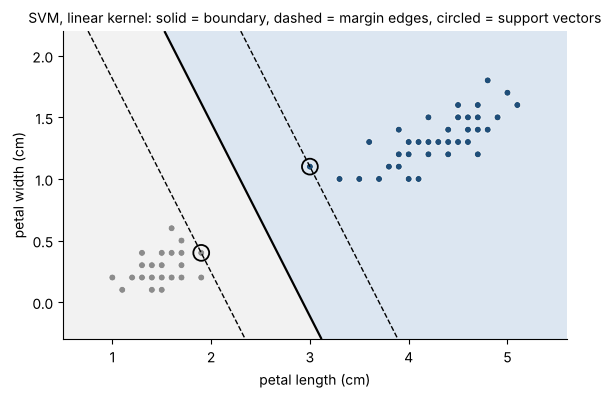

In [3]:
def draw_svm(m, X, y, ax, title=None, colors=(GRAY, BLUE)):
    xx, yy = np.meshgrid(np.linspace(X.iloc[:, 0].min() - 0.5, X.iloc[:, 0].max() + 0.5, 300), np.linspace(X.iloc[:, 1].min() - 0.4, X.iloc[:, 1].max() + 0.4, 300))
    grid_df = pd.DataFrame({X.columns[0]: xx.ravel(), X.columns[1]: yy.ravel()})
    score = m.decision_function(grid_df).reshape(xx.shape)
    ax.contourf(xx, yy, score, levels=[-1000, 0, 1000], colors=["#F2F2F2", "#DCE6F1"])
    ax.contour(xx, yy, score, levels=[-1, 0, 1], colors=["black", "black", "black"], linestyles=["--", "-", "--"], linewidths=[1, 1.6, 1])
    ax.scatter(X.iloc[:, 0], X.iloc[:, 1], c=np.where(np.asarray(y) == np.unique(y)[1], colors[1], colors[0]), s=24, edgecolor="white", linewidth=0.5)
    ax.scatter(m.support_vectors_[:, 0], m.support_vectors_[:, 1], s=130, facecolors="none", edgecolors="black", linewidths=1.3)
    ax.set_xlabel(X.columns[0]); ax.set_title(title, fontsize=10)

fig, ax = plt.subplots(figsize=(6.5, 4))
draw_svm(svm_easy, X_easy, y_easy, ax, "SVM, linear kernel: solid = boundary, dashed = margin edges, circled = support vectors")
ax.set_ylabel(cols[1]); plt.show()

**Giải thích từng dòng**

- `def draw_svm(m, X, y, ax, title=None, colors=(GRAY, BLUE)):`: hàm vẽ dùng nhiều lần: nhận mô hình SVM, bảng hai cột, nhãn, khung vẽ.
- `score = m.decision_function(grid_df).reshape(xx.shape)`: **mới với SVM:** `decision_function` cho **điểm có dấu** của mỗi điểm lưới: 0 ở đường biên, **+1 và −1 ở hai mép lề**, dương về phía nhóm 1, âm về phía nhóm 0. Độ lớn tỉ lệ với khoảng cách tới đường biên.
- `ax.contour(..., levels=[-1, 0, 1], linestyles=["--", "-", "--"], ...)`: vẽ ba đường: biên (nét liền, mức 0) và hai mép lề (nét đứt, mức −1 và +1).
- `ax.scatter(m.support_vectors_[:, 0], ..., facecolors="none", edgecolors="black")`: khoanh vòng tròn rỗng quanh các **vectơ hỗ trợ**.
- `c=np.where(np.asarray(y) == np.unique(y)[1], colors[1], colors[0])`: (đã học `np.where`) tô nhóm đứng sau xanh, nhóm đứng trước xám; `np.unique(y)` là danh sách các nhãn khác nhau theo thứ tự.

**Cách đọc**

- **Con số:** mô hình có **2 vectơ hỗ trợ** (mỗi loài một cây): một cây versicolor và một cây setosa. Lề rộng **1,30 cm**.
- **Bức tranh:** đường liền đen chạy đúng **giữa** hai đám điểm; hai đường nét đứt song song nằm **sát điểm gần nhất của mỗi phía**; hai điểm được khoanh tròn chính là hai điểm chạm vào nét đứt. Toàn bộ đám đông còn lại nằm xa, bình yên, *không ảnh hưởng gì đến vị trí đường rào*.
- **Ý nghĩa:** hàng rào được đặt **sao cho khoảng trống hai bên bằng nhau và rộng nhất**. Cây trồng lệch một chút (vì đo lỗi hay vì mẫu mới) vẫn nằm đúng bên: đó là lý do SVM *chịu nhiễu tốt*.

**Mang về chặng 1:** SVM chọn đường biên có **lề rộng nhất**. Điểm số `decision_function` là 0 ở biên, ±1 ở mép lề.

## Chặng 2: Vectơ hỗ trợ, chỉ vài điểm sát ranh giới quyết định tất cả

**Câu hỏi:** ta nói "chỉ hai cây quyết định đường rào". Kiểm chứng được không?

Cách kiểm: **vứt hết các cây khác**, chỉ giữ hai vectơ hỗ trợ, học lại. Nếu lời ta nói đúng thì đường rào *y hệt*.

In [4]:
keep = svm_easy.support_
svm_two = SVC(kernel="linear", C=1000).fit(X_easy.iloc[keep], y_easy.iloc[keep])
print("trained on all", len(X_easy), "plants :", svm_easy.coef_[0].round(4), svm_easy.intercept_.round(4))
print("trained on just", len(keep), "plants :", svm_two.coef_[0].round(4), svm_two.intercept_.round(4))

trained on all 100 plants : [1.2941 0.8235] [-3.7882]
trained on just 2 plants : [1.2941 0.8235] [-3.7882]


**Giải thích từng dòng**

- `keep = svm_easy.support_`: **mới:** `support_` là **vị trí** (số thứ tự dòng) của các vectơ hỗ trợ trong dữ liệu học.
- `X_easy.iloc[keep], y_easy.iloc[keep]`: (đã học `iloc` với danh sách vị trí) chỉ giữ các cây hỗ trợ.

**Cách đọc:** hai bộ `coef_`, `intercept_` **giống nhau đến từng chữ số lẻ** ([1.294, 0.824], -3,788). Đường rào của SVM được xác định *hoàn toàn* bởi các điểm sát lề. Mô hình "nén" cả 100 cây thành 2 cây then chốt.

Hệ quả thực tế: ta có thể **thêm hay bớt** hàng trăm cây nằm xa ranh giới mà đường rào không nhúc nhích. Ngược lại, **một cây lạ nằm sát ranh giới** có thể kéo đường rào đi nơi khác. Hồi quy logistic (C1) thì khác: *mọi* điểm đều góp phần, dù ít hay nhiều.

Chuyển sang cặp khó hơn, **versicolor và virginica** (hai loài lẫn nhau như ở C1), để thấy vai trò của núm `C`.

**Mang về chặng 2:** SVM chỉ phụ thuộc vào **vectơ hỗ trợ** (những điểm chạm hoặc lấn lề); các điểm xa ranh giới không ảnh hưởng. `support_`, `support_vectors_`, `n_support_` cho biết ai là họ.

## Chặng 3: Núm `C`, chấp nhận bao nhiêu điểm lấn lề

**Câu hỏi:** nếu hai nhóm *lẫn vào nhau* (không tách thẳng được) thì "lề rộng nhất" vô nghĩa. Làm sao?

SVM cho phép **một số điểm lấn vào lề, thậm chí sang bên kia**, nhưng mỗi điểm lấn bị **phạt**. Núm `C` là **độ nặng của khoản phạt**:

- **`C` rất lớn:** phạt nặng, máy cố *không cho điểm nào lấn*: lề hẹp, ôm sát từng điểm lẻ (dễ **quá khớp**).
- **`C` nhỏ:** phạt nhẹ, máy chấp nhận nhiều điểm lấn đổi lấy lề rộng thoáng: ranh giới đơn giản hơn (dễ **dưới khớp**).

Chú ý `C` ở SVM cùng chiều với `C` ở logistic (C1): **nhỏ là kìm chặt, lớn là thả lỏng** (ngược với `alpha` ở Ridge B6).

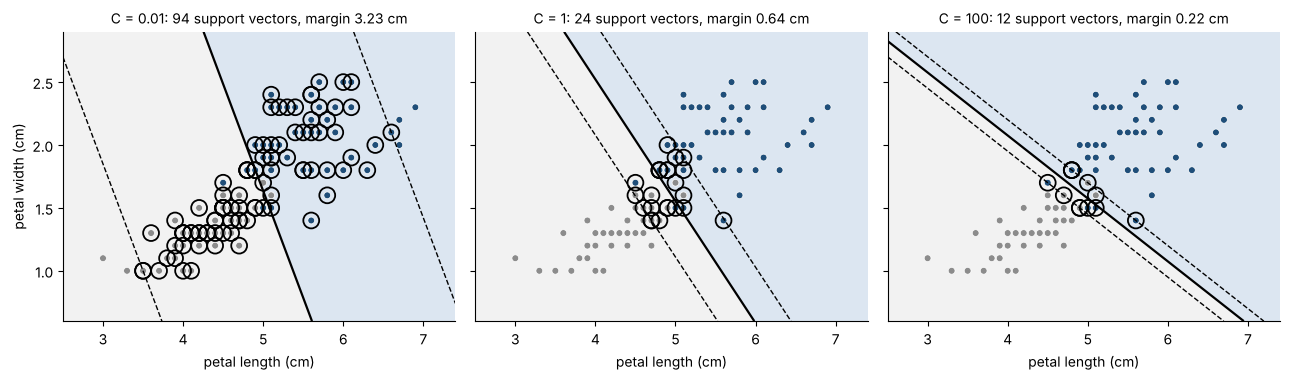

In [5]:
hard = iris[iris["target"] > 0]
X_hard, y_hard = hard[cols], (hard["target"] == 2).astype(int)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, C in zip(axes, [0.01, 1, 100]):
    m = SVC(kernel="linear", C=C).fit(X_hard, y_hard)
    draw_svm(m, X_hard, y_hard, ax, f"C = {C}: {m.n_support_.sum()} support vectors, margin {2 / np.linalg.norm(m.coef_[0]):.2f} cm")
axes[0].set_ylabel(cols[1])
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `hard = iris[iris["target"] > 0]`: hai loài 1 và 2 (versicolor, virginica) như ở C1.
- `for ax, C in zip(axes, [0.01, 1, 100]):`: ba khung: phạt rất nhẹ, vừa, rất nặng.
- `m.n_support_.sum()`: tổng số vectơ hỗ trợ của cả hai nhóm.

In [6]:
rows = []
cv_check = __import__("sklearn.model_selection", fromlist=["x"])
cv = cv_check.RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
for C in [0.01, 0.1, 1, 10, 100]:
    m = SVC(kernel="linear", C=C).fit(X_hard, y_hard)
    s = cv_check.cross_val_score(SVC(kernel="linear", C=C), X_hard, y_hard, cv=cv)
    rows.append({"C": C, "support vectors": int(m.n_support_.sum()), "margin (cm)": round(2 / np.linalg.norm(m.coef_[0]), 2), "CV accuracy": round(s.mean(), 3), "CV std": round(s.std(), 3)})
print(pd.DataFrame(rows).to_string(index=False))

     C  support vectors  margin (cm)  CV accuracy  CV std
  0.01               94         3.23        0.943   0.050
  0.10               50         1.31        0.938   0.049
  1.00               24         0.64        0.948   0.055
 10.00               15         0.36        0.940   0.062
100.00               12         0.22        0.929   0.060


**Giải thích từng dòng**

- `cv_check = __import__("sklearn.model_selection", fromlist=["x"])`: cách gọn để dùng `cross_val_score` và `RepeatedStratifiedKFold` mà không phải viết dòng `import` riêng (bạn đã gặp chúng ở C1). Từ nay trong bài ta dùng `cv_check.` đứng trước tên hàm.
- `cv = cv_check.RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)`: cách đo 50 điểm quen thuộc.
- `rows.append({...})`: gom mỗi giá trị `C` thành một dòng của bảng kết quả.

**Cách đọc**

- **Con số:** khi `C` tăng từ 0,01 lên 100, số vectơ hỗ trợ giảm từ **94** xuống **12** và lề thu hẹp từ **3,23** cm xuống **0,22** cm. Độ đúng kiểm định chéo: 0,943, 0,938, 0,948, 0,940, 0,929 (từ `C` nhỏ đến lớn), độ lệch chuẩn khoảng 0,05.
- **Bức tranh:** ở `C = 0,01` hai đường nét đứt cách nhau xa, *hầu như cả đám điểm giáp ranh nằm trong lề* (vì thế gần 100 vectơ hỗ trợ). Ở `C = 100` lề thu lại sát đường rào, chỉ còn vài điểm chạm lề. Hướng đường rào thay đổi nhẹ giữa các khung: đường rào *bám sát vài cây lẻ* khi `C` lớn.
- **Ý nghĩa:** `C` là siêu tham số điều chỉnh độ **mượt** (nhớ B5, B6, C1, C3...): một lần nữa là *cân giữa ôm sát dữ liệu và giữ đơn giản*. Cao nguyên ở giữa (0,01 đến 10 đều quanh 0,93 đến 0,95): chênh lệch **nằm trong dao động** nên chọn `C` bằng kiểm định chéo, đừng chọn bằng cảm tính.
- **Hai loại "đúng" của vectơ hỗ trợ:** số vectơ hỗ trợ nhiều thường là dấu hiệu của *lề rộng, mô hình đơn giản*; số ít là *lề hẹp, mô hình sát dữ liệu*. Điều này ngược với phản xạ "ít hơn thì đơn giản hơn" nên đáng nhớ.

**Mang về chặng 3:** `C` là độ nặng của khoản phạt cho điểm lấn lề: nhỏ thì lề rộng và chấp nhận sai, lớn thì lề hẹp và ôm sát. Chọn bằng kiểm định chéo.

## Chặng 4: Hạt nhân (kernel) RBF và núm `gamma`, uốn cong đường rào

**Câu hỏi:** nếu hai nhóm **xoắn vào nhau** như hai vầng trăng khuyết thì sao?

Dữ liệu **tự sinh** `make_moons` tạo hai nửa vầng trăng lồng nhau; không đường thẳng nào tách được. Ta so SVM thẳng, hồi quy logistic và SVM với **kernel RBF**.

In [7]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
Xm, ym = make_moons(n_samples=300, noise=0.25, random_state=0)
Xm = pd.DataFrame(Xm, columns=["x1", "x2"])
Xm_train, Xm_test, ym_train, ym_test = train_test_split(Xm, ym, test_size=0.25, random_state=42, stratify=ym)
contenders = {
    "logistic (straight)": LogisticRegression(),
    "SVM linear": SVC(kernel="linear"),
    "SVM rbf (default)": SVC(kernel="rbf"),
}
scores_moons = {name: cv_check.cross_val_score(m, Xm_train, ym_train, cv=cv) for name, m in contenders.items()}
print(pd.DataFrame({n: {"CV mean": s.mean(), "CV std": s.std()} for n, s in scores_moons.items()}).T.round(3).to_string())

                     CV mean  CV std
logistic (straight)    0.841   0.052
SVM linear             0.841   0.050
SVM rbf (default)      0.963   0.026


**Giải thích từng dòng**

- `make_moons(n_samples=300, noise=0.25, random_state=0)`: **mới:** `make_moons` tự sinh hai vầng trăng khuyết lồng nhau; `noise` là độ nhòe.
- `Xm = pd.DataFrame(Xm, columns=["x1", "x2"])`: bọc vào bảng có tên cột để `draw_svm` dùng được.
- `SVC(kernel="rbf")`: **mới:** `kernel="rbf"` (radial basis function, "hàm cơ sở xuyên tâm"), mặc định của `SVC`.

**Cách đọc:** logistic 0,841, SVM thẳng 0,841, **SVM RBF 0,963**. Hai mô hình thẳng đứng sát nhau; RBF vượt xa.

**Kernel làm gì?** Không cần hiểu toán, hình dung thế này. Kernel RBF đo *độ giống* giữa hai điểm bằng một **"quầng ảnh hưởng" hình chuông** quanh mỗi điểm: gần thì giống nhiều, xa thì giống gần như bằng 0. SVM cộng các quầng đó lại để ra **bản đồ điểm số cong**. Đường biên là nơi các quầng của hai nhóm cân bằng nhau. Mẹo "kernel" cho phép làm như thể ta đã thêm vô số cột mới (như `PolynomialFeatures` ở B5) mà **không phải tạo ra chúng**.

**Núm vặn `gamma`** là **độ hẹp của quầng**: `gamma` lớn thì quầng *hẹp* (mỗi điểm chỉ ảnh hưởng vùng rất gần: đường rào uốn lượn ôm từng điểm, dễ quá khớp), `gamma` nhỏ thì quầng *rộng* (mọi điểm ảnh hưởng xa, đường rào trơn, dễ dưới khớp).

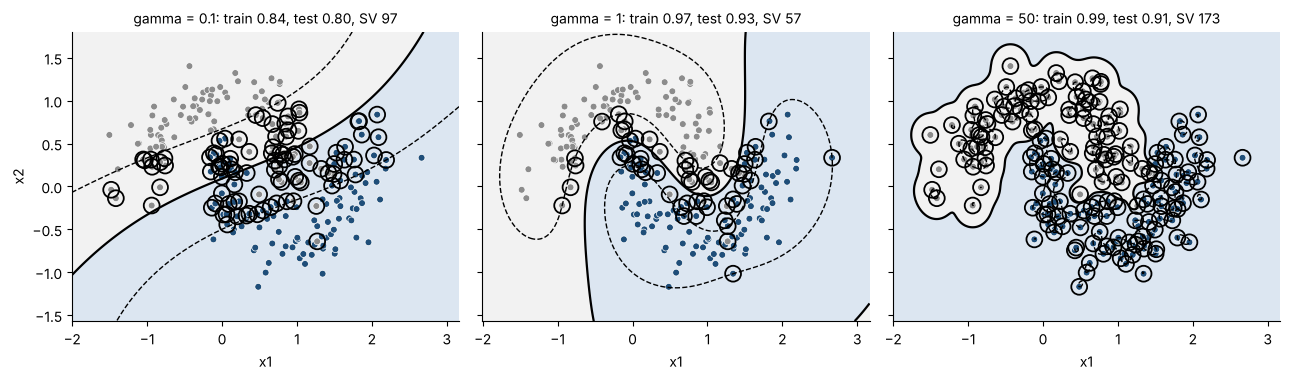

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, gm in zip(axes, [0.1, 1, 50]):
    m = SVC(kernel="rbf", C=1, gamma=gm).fit(Xm_train, ym_train)
    draw_svm(m, Xm_train, ym_train, ax, f"gamma = {gm}: train {m.score(Xm_train, ym_train):.2f}, test {m.score(Xm_test, ym_test):.2f}, SV {m.n_support_.sum()}")
axes[0].set_ylabel("x2")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `SVC(kernel="rbf", C=1, gamma=gm)`: **mới:** núm `gamma`: độ hẹp của quầng ảnh hưởng. Mặc định `gamma="scale"` tự đặt theo độ phân tán của dữ liệu. Ở đây thử ba mức: 0,1 (rộng), 1 (vừa), 50 (rất hẹp).

**Cách đọc**

- **Con số:** `gamma = 0,1`: train 0,84, test 0,80 (dưới khớp). `gamma = 1`: train 0,97, test 0,93. `gamma = 50`: train 0,99, test 0,91.
- **Bức tranh:** ở `gamma = 0,1` đường rào **cong rất nhẹ, gần như thẳng**: quầng quá rộng nên không uốn theo hai vầng trăng được (dưới khớp). Ở `gamma = 1` đường rào uốn **mềm mại theo hai vầng trăng**. Ở `gamma = 50` đường rào **ôm sát từng điểm xám**, viền ngoằn ngoèo và hầu hết điểm đều là vectơ hỗ trợ: máy *thuộc lòng* dữ liệu học (train cao, test tụt).
- **Ý nghĩa:** **hai núm đi cùng nhau:** `C` (chấp nhận lỗi) và `gamma` (độ cong). Cả hai đều là cách chỉnh cùng một thanh trượt *đơn giản ↔ phức tạp*. Tìm cặp tốt nhất bằng kiểm định chéo trên **lưới** hai chiều:

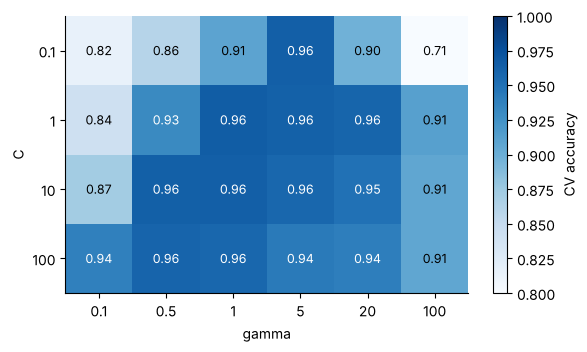

best cell: C = 1, gamma = 1 -> CV accuracy 0.965


In [9]:
Cs = [0.1, 1, 10, 100]
gammas = [0.1, 0.5, 1, 5, 20, 100]
grid_scores = np.array([[cv_check.cross_val_score(SVC(C=C, gamma=gm), Xm_train, ym_train, cv=cv).mean() for gm in gammas] for C in Cs])
plt.figure(figsize=(6.5, 3.6))
plt.imshow(grid_scores, cmap="Blues", vmin=0.8, vmax=1.0, aspect="auto")
plt.xticks(range(len(gammas)), gammas); plt.yticks(range(len(Cs)), Cs)
for i in range(len(Cs)):
    for j in range(len(gammas)):
        plt.text(j, i, f"{grid_scores[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if grid_scores[i, j] > 0.93 else "black")
plt.xlabel("gamma"); plt.ylabel("C"); plt.colorbar(label="CV accuracy"); plt.show()
best_i, best_j = np.unravel_index(grid_scores.argmax(), grid_scores.shape)
print(f"best cell: C = {Cs[best_i]}, gamma = {gammas[best_j]} -> CV accuracy {grid_scores.max():.3f}")

**Giải thích từng dòng**

- `grid_scores = np.array([[... for gm in gammas] for C in Cs])`: hai vòng lặp lồng nhau trong ngoặc vuông cho ra **bảng điểm** (hàng là `C`, cột là `gamma`): 4 × 6 = 24 mô hình, mỗi mô hình đo bằng 50 điểm kiểm định chéo.
- `plt.imshow(grid_scores, cmap="Blues", vmin=0.8, vmax=1.0, aspect="auto")`: (đã học ở C4) tô bảng số thành **bản đồ nhiệt**: ô càng đậm điểm càng cao. `vmin`, `vmax` cố định thang màu từ 0,8 đến 1,0.
- `plt.text(j, i, f"{grid_scores[i, j]:.2f}", ...)`: ghi số vào từng ô; đổi màu chữ để dễ đọc trên nền đậm.
- `np.unravel_index(grid_scores.argmax(), grid_scores.shape)`: **mới:** `argmax` cho vị trí trong dãy duỗi thẳng; `unravel_index` đổi về (hàng, cột) của bảng.

**Cách đọc**

- **Con số:** ô tốt nhất là `C = 1`, `gamma = 1` với **0,965**. Cả hai góc cực đoan đều thấp: cột `gamma = 0,1` (quầng quá rộng) thấp nhất ở `C` nhỏ: 0,82, còn cột `gamma = 100` (quầng quá hẹp) chỉ đạt 0,91 dù `C` lớn.
- **Bức tranh:** vùng đậm nằm thành một **dải chéo** từ giữa trên đến giữa dưới: `gamma` lớn hơn thì cần `C` nhỏ hơn để bù, và ngược lại. Hai núm *gây nhiễu* lẫn nhau, không chỉnh độc lập được.
- **Ý nghĩa:** đây là hình dạng của bài toán "**tìm siêu tham số**" mà phần D sẽ làm một cách bài bản (`GridSearchCV`). Cẩn thận: ô tốt nhất trên lưới chỉ hơn ô lân cận vài phần nghìn, nằm trong nhiễu; đừng tôn thờ nó, chỉ cần tránh các góc.

**Mang về chặng 4:** kernel RBF cho đường rào cong; `gamma` là độ hẹp của quầng (lớn thì quá khớp), `C` là độ nặng của khoản phạt; hai núm đi cùng nhau và chọn trên lưới bằng kiểm định chéo.

## Chặng 5: Chuẩn hóa bắt buộc, và so với các mô hình đã học

**Câu hỏi:** SVM đo "quầng ảnh hưởng" theo khoảng cách. Vậy nó có cùng điểm yếu với k-NN (C3) không?

Có. Cả lề lẫn quầng RBF đều tính từ **khoảng cách**, nên cột có số to sẽ lấn át cột khác. Thử trên bộ ung thư vú (30 cột thang đo rất khác nhau):

In [10]:
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
bc = load_breast_cancer(as_frame=True)
Xb, yb = bc.data, 1 - bc.target
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.25, random_state=42, stratify=yb)
board_models = {
    "SVM rbf, raw columns": SVC(),
    "SVM rbf, scaled": make_pipeline(StandardScaler(), SVC()),
    "SVM rbf, scaled, C=10": make_pipeline(StandardScaler(), SVC(C=10)),
    "SVM linear, scaled": make_pipeline(StandardScaler(), SVC(kernel="linear")),
    "logistic, scaled": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "k-NN k=9, scaled": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9)),
    "tree depth 3": DecisionTreeClassifier(max_depth=3, random_state=0),
}
board = {name: cv_check.cross_val_score(m, Xb_train, yb_train, cv=cv) for name, m in board_models.items()}
print(pd.DataFrame({n: {"CV mean": s.mean(), "CV std": s.std()} for n, s in board.items()}).T.round(3).to_string())

                       CV mean  CV std
SVM rbf, raw columns     0.909   0.031
SVM rbf, scaled          0.971   0.014
SVM rbf, scaled, C=10    0.975   0.017
SVM linear, scaled       0.969   0.015
logistic, scaled         0.975   0.016
k-NN k=9, scaled         0.960   0.019
tree depth 3             0.927   0.025


**Giải thích từng dòng**

- `SVC()`: SVM mặc định (RBF, `C=1`, `gamma="scale"`) trên **cột thô**.
- `make_pipeline(StandardScaler(), SVC(C=10))`: chuẩn hóa rồi SVM với `C` lớn hơn.
- `board = {name: cv_check.cross_val_score(...) for ...}`: (đã học) 50 điểm cho mỗi ứng viên, trên cùng cách chia.

**Cách đọc**

- **Con số:** SVM RBF trên cột thô: **0,909**. Sau khi chuẩn hóa: **0,971**, và với `C = 10`: **0,975**. Cạnh đó: SVM thẳng 0,969, logistic 0,975, k-NN 0,960, cây ba tầng 0,927.
- **Bức tranh:** chuẩn hóa nhấc SVM từ khoảng 0,91 lên 0,97; sau đó SVM, logistic và k-NN **chen sát nhau** quanh 0,97 đến 0,975, còn cây nông tụt sau (đúng như C5).
- **Ý nghĩa:** với dữ liệu *đã sạch và tách khá tốt* như bộ ung thư vú, SVM RBF **không** hơn logistic: chênh lệch nhỏ hơn độ lệch chuẩn. Kernel cong chỉ có lợi khi ranh giới thật sự cong. Đây là lời nhắc: *mô hình phức tạp hơn không tự động tốt hơn*; hãy dùng logistic làm mốc.

SVM có hai cách "nói" khác nhau ngoài nhãn:

In [11]:
svm_pipe = make_pipeline(StandardScaler(), SVC(C=10)).fit(Xb_train, yb_train)
scores_test = svm_pipe.decision_function(Xb_test)
from sklearn.metrics import roc_auc_score
print("decision_function (first 6 test cases):", scores_test[:6].round(2), "| positive = predicted malignant")
print("AUC computed straight from decision_function:", round(roc_auc_score(yb_test, scores_test), 4))
try:
    svm_pipe.predict_proba(Xb_test)
except Exception as e:
    print("predict_proba ->", type(e).__name__, ":", str(e)[:70])
from sklearn.calibration import CalibratedClassifierCV
prob_pipe = make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(C=10), ensemble=False)).fit(Xb_train, yb_train)
print("with CalibratedClassifierCV, first 6 P(malignant):", prob_pipe.predict_proba(Xb_test)[:6, 1].round(3))

decision_function (first 6 test cases): [ 0.35 -2.    2.43 -0.41 -1.57 -2.7 ] | positive = predicted malignant
AUC computed straight from decision_function: 0.9937
predict_proba -> AttributeError : This 'Pipeline' has no attribute 'predict_proba'
with CalibratedClassifierCV, first 6 P(malignant): [0.759 0.002 1.    0.222 0.007 0.   ]


**Giải thích từng dòng**

- `svm_pipe.decision_function(Xb_test)`: với pipeline, `decision_function` đi qua cả bước chuẩn hóa. Điểm số có dấu: dương là nhóm 1 (ác), âm là nhóm 0; **độ lớn là khoảng cách tới đường biên** (không phải xác suất).
- `roc_auc_score(yb_test, scores_test)`: (đã học ở C2) AUC chỉ cần **thứ tự xếp hạng**, không cần xác suất: đưa thẳng điểm `decision_function` vào được.
- `try: ... except Exception as e: ...`: **mới:** `try/except` thử chạy một lệnh, *nếu lỗi thì không dừng cả chương trình* mà chạy phần `except`. Ở đây ta *cố ý* gọi `predict_proba` của SVM mặc định để xem thông báo lỗi.
- `CalibratedClassifierCV(SVC(C=10), ensemble=False)`: **mới:** bộ **hiệu chỉnh xác suất** bọc quanh SVM: học thêm một bước đổi điểm `decision_function` thành xác suất (bằng kiểm định chéo nội bộ). Cách cũ `SVC(probability=True)` đã bị sklearn đánh dấu loại bỏ nên ta dùng cách này.

**Cách đọc:** `decision_function` cho điểm số có dấu, dùng ngay được để xếp hạng (AUC 0,994) nhưng **không phải xác suất**. Mặc định SVM **không có** `predict_proba` (báo lỗi `AttributeError`). Bọc bằng `CalibratedClassifierCV` thì có, nhưng phải trả giá bằng tốc độ, và xác suất đó chỉ là *quy đổi sau lưng* (không phải thứ SVM tối ưu). Nếu quyết định của bạn phụ thuộc vào mức chắc chắn (ví dụ chọn ngưỡng theo chi phí như C2) thì logistic là lựa chọn tự nhiên hơn.

**Hồ sơ của mô hình:**

| Mục | `SVC` |
|---|---|
| **Nó là gì** | Đường biên có lề rộng nhất; kernel cho phép biên cong |
| **Dùng khi nào** | Dữ liệu vừa phải (đến vài chục nghìn dòng), ranh giới có thể cong, nhiều cột |
| **`X`** | Bảng số, **bắt buộc chuẩn hóa** |
| **`y`** | Nhãn nhóm |
| **Ô trống `NaN` trong `X`** | **Không chịu**: điền hoặc bỏ trước |
| **Module sklearn** | `sklearn.svm.SVC` (và `LinearSVC` cho bản thẳng, nhanh hơn với dữ liệu lớn) |
| **Sau `fit` có gì** | `support_vectors_`, `n_support_`, `dual_coef_`; **`coef_` chỉ khi `kernel="linear"`** |
| **Siêu tham số chính** | `C`, `kernel`, `gamma` (RBF) |

**Mang về chặng 5:** SVM phải **chuẩn hóa**; với dữ liệu tách tốt, SVM RBF không hơn logistic; `decision_function` là điểm xếp hạng (không phải xác suất); bọc `CalibratedClassifierCV` cho xác suất nhưng chậm.

## Chặng 6: Giới hạn, chậm khi nhiều dữ liệu, không có xác suất sẵn

**Câu hỏi:** SVM có đáng dùng cho dữ liệu lớn không?

Đo thời gian `fit` khi số dòng tăng gấp bốn lần mỗi bước (dữ liệu tự sinh hình trăng):

In [12]:
import time
sizes = [500, 2000, 8000]
times = []
for n in sizes:
    Xs, ys = make_moons(n_samples=n, noise=0.3, random_state=0)
    start = time.perf_counter()
    SVC().fit(Xs, ys)
    times.append(time.perf_counter() - start)
for n, t in zip(sizes, times):
    print(f"n = {n:>5}: fit took {t:.3f} s")
print(f"4x more rows -> time x{times[1] / times[0]:.0f}, then x{times[2] / times[1]:.0f}")

n =   500: fit took 0.003 s
n =  2000: fit took 0.023 s
n =  8000: fit took 0.376 s
4x more rows -> time x7, then x16


**Giải thích từng dòng**

- `import time`: thư viện `time` có đồng hồ: `time.perf_counter()` trả thời điểm hiện tại (giây) với độ chính xác cao. Trừ hai thời điểm cho thời gian chạy.
- `start = time.perf_counter(); SVC().fit(Xs, ys); times.append(time.perf_counter() - start)`: đo thời gian `fit`.
- `f"n = {n:>5}: ..."`: `:>5` canh phải trong 5 ký tự.

**Cách đọc:** trên máy chạy bài này, 500 dòng mất khoảng 0,004 giây, 2000 dòng khoảng 0,026 giây, 8000 dòng khoảng 0,387 giây. Tăng số dòng **4 lần** làm thời gian tăng khoảng **6 đến 15 lần**: *nhanh hơn tuyến tính nhiều* (xấp xỉ theo bình phương số dòng hoặc hơn). Con số tuyệt đối thay đổi theo máy, nhưng **tỉ lệ tăng** là bản chất của SVM kernel. Với vài trăm nghìn dòng trở lên nên dùng `LinearSVC`, logistic hoặc các mô hình ensemble (phần E).

**Ba giới hạn nữa:** (1) mặc định **không có xác suất** (chặng 5); (2) **chọn kernel và núm vặn cần kinh nghiệm**, lưới tìm hai chiều tốn thời gian; (3) **khó giải thích**: không có "tờ quy tắc" như cây, và với kernel cong không có `coef_`.

## Phán quyết và bài học nghề

**Phán quyết cho chị Mai.** Với **hai loài dễ tách** (setosa và versicolor), dùng SVM thẳng: hai cây then chốt đã đủ xác định đường rào, và lề rộng tức là *an toàn trước sai số đo*. Với **cặp lẫn nhau** (versicolor, virginica), dùng `C` vừa phải (khoảng 1) chọn bằng kiểm định chéo, kỳ vọng độ đúng khoảng 94 trên 100, ngang logistic ở C1. Đừng chạy theo kernel cong khi ranh giới thật gần như thẳng.

**Bài học nghề.**

1. **SVM = đường biên có lề rộng nhất.** `decision_function` là 0 ở biên, ±1 ở mép lề.
2. **Chỉ vectơ hỗ trợ quyết định**: các điểm xa biên không ảnh hưởng.
3. **`C` là độ nặng khoản phạt cho điểm lấn lề**; nhỏ là lề rộng chấp nhận sai, lớn là ôm sát.
4. **Kernel RBF cho đường cong**; `gamma` là độ hẹp của quầng (lớn thì quá khớp); chọn `C` và `gamma` cùng nhau trên lưới.
5. **Bắt buộc chuẩn hóa.**
6. **Không có xác suất sẵn, chậm khi nhiều dữ liệu, khó giải thích.** Chỉ dùng khi ranh giới cong thật sự hoặc dữ liệu vừa phải nhiều cột.

**Một điều thành thật:** trong thực hành hiện đại, trên dữ liệu bảng (như bảng khách hàng, bảng xét nghiệm), SVM thường *không* là lựa chọn đầu tiên; các mô hình ensemble (phần E) thường thắng với ít công chỉnh hơn. SVM vẫn đáng học vì ý tưởng **lề** và **kernel** xuất hiện ở nhiều nơi khác.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | SVM chọn đường biên có lề rộng nhất; `decision_function` là 0 ở biên, ±1 ở mép lề. |
| 2 | Chỉ vectơ hỗ trợ (điểm sát hoặc lấn lề) quyết định đường biên. |
| 3 | `C` là độ nặng khoản phạt: nhỏ thì lề rộng, lớn thì ôm sát (quá khớp). |
| 4 | Kernel RBF cho biên cong; `gamma` là độ hẹp của quầng ảnh hưởng; chọn cùng `C` bằng lưới và kiểm định chéo. |
| 5 | Bắt buộc chuẩn hóa; mặc định không có xác suất (bọc `CalibratedClassifierCV` thì có nhưng chậm). |
| 6 | Thời gian tăng nhanh hơn tuyến tính theo số dòng; khó giải thích; không phải lựa chọn đầu tiên cho dữ liệu bảng. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Khoảng trống giữa biên và điểm gần nhất | lề (margin) | `2 / np.linalg.norm(coef_)` |
| Điểm chạm hoặc lấn lề | vectơ hỗ trợ (support vector) | `support_vectors_`, `n_support_` |
| Độ nặng khoản phạt cho điểm lấn lề | tham số điều chuẩn C | `C=` |
| Cách đo độ giống giữa hai điểm | kernel (hạt nhân) | `kernel="rbf"`, `"linear"` |
| Độ hẹp của quầng ảnh hưởng quanh mỗi điểm | gamma | `gamma=` |
| Điểm số có dấu, độ lớn là khoảng cách tới biên | hàm quyết định | `decision_function` |
| Bật xác suất cho SVM | hiệu chỉnh xác suất | `CalibratedClassifierCV` |
| Thử nhiều cặp (C, gamma) trên lưới | tìm lưới siêu tham số | bản đồ nhiệt kiểm định chéo |
| SVM nhanh cho dữ liệu lớn, chỉ biên thẳng | SVM tuyến tính | `LinearSVC` |

**Thử thách tự làm**

1. Ở chặng 2, thêm một cây versicolor **nằm xa** hàng rào rồi học lại. Đường rào có đổi không? Rồi thêm một cây **sát hàng rào**. Điều gì xảy ra? Vì sao?
2. Ở chặng 4, thử `kernel="poly"` với `degree=3` trên hai vầng trăng. So độ đúng với RBF. Hình dạng đường rào khác thế nào?
3. Kể chuyện với dữ liệu khác: dùng `load_wine` (C3). Chuẩn hóa rồi dùng SVM RBF, tìm `C` và `gamma` bằng lưới 4 × 4. So với k-NN ở C3.

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích lề và vì sao chọn lề rộng nhất.
- [ ] Chỉ ra vectơ hỗ trợ trong hình và nói vì sao chúng quyết định đường biên.
- [ ] Giải thích `C` và dự đoán điều gì xảy ra khi tăng hoặc giảm `C`.
- [ ] Giải thích `gamma` của RBF và dấu hiệu quá khớp.
- [ ] Biết phải chuẩn hóa, và `SVC` mặc định không có `predict_proba`.
- [ ] Biết khi nào nên và không nên dùng SVM.

## Phần thưởng (Tip pro): Vì sao `C` và `gamma` được thử theo thang logarit, và `GridSearchCV` là gì


Cả `C` và `gamma` có ý nghĩa theo **bậc độ lớn** (0,1; 1; 10; 100...), nên người ta thử theo **cấp số nhân** (`np.logspace`, đã gặp ở B6), không thử cách đều (0,1; 0,2; 0,3...). Cái bảng 4 × 6 ở chặng 4 ta tự lặp bằng tay; sklearn đóng gói việc đó trong **`GridSearchCV`**: đưa cho nó mô hình và một lưới siêu tham số, nó thử mọi tổ hợp bằng kiểm định chéo rồi báo ô tốt nhất. Phần D sẽ dạy kỹ (kèm cảnh báo: chọn xong còn phải mở tập thi một lần để kiểm). Thử sơ qua:

In [13]:
from sklearn.model_selection import GridSearchCV
search = GridSearchCV(SVC(), {"C": [0.1, 1, 10, 100], "gamma": [0.1, 0.5, 1, 5, 20, 100]}, cv=5)
search.fit(Xm_train, ym_train)
print("best:", search.best_params_, "| CV accuracy:", round(search.best_score_, 3))

best: {'C': 10, 'gamma': 1} | CV accuracy: 0.969


**Giải thích từng dòng**

- `GridSearchCV(SVC(), {...}, cv=5)`: **mới (xem trước):** nhận mô hình, từ điển *tên siêu tham số → danh sách giá trị*, và cách kiểm định chéo (`cv=5` là 5 phần). Nó thử **mọi tổ hợp**.
- `search.best_params_, search.best_score_`: tổ hợp tốt nhất và điểm kiểm định chéo của nó. (Sau `fit`, `search` còn là một mô hình đã học lại trên toàn tập học bằng tổ hợp tốt nhất.)